# Machine Learning
## TP N° 02 — Organisation et préparation de l'environnement

---

### A. Organisation des fichiers

Le dossier **TP2** doit contenir les fichiers suivants :

- **Lab02_starter.ipynb** : Notebook contenant les exercices du TP.
- **requirements.txt** : Liste des bibliothèques Python nécessaires.
- **data/** : Dossier contenant le fichier `titanic.csv`.

<p align="center">
    <img src="organisation.png" width="500">
</p>

**Structure du projet :**

```text
TP2/
│
├── Lab02_starter.ipynb
├── requirements.txt
│
└── data/
    └── titanic.csv

## B. Préparation de l'environnement

### Étape 1 — Ouvrir le projet dans VS Code

1. Lancer **Visual Studio Code**.
2. Sélectionner `File → Open Folder`.
3. Choisir le dossier `TP2`.

### Étape 2 — Ouvrir le terminal

Dans VS Code, sélectionner :

`Terminal → New Terminal`

### Étape 3 — Vérifier Python et PIP

Exécuter les commandes suivantes :

```bash
python --version
python -m pip --version
```
<p align="center">
    <img src="env.png" width="500">
</p>

> **Remarque :** Le TP nécessite **Python 3.10 ou une version ultérieure**.

### Étape 4 — Créer un environnement virtuel

Exécuter la commande suivante :

```bash
python -m venv .venv
```

### Étape 5 — Installer les bibliothèques nécessaires

**Méthode 1 : À partir du fichier `requirements.txt`**

```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
```

**Méthode 2 : Installation directe**

Ou bien, installer toutes les bibliothèques nécessaires avec une seule commande :

```powershell
.\.venv\Scripts\python.exe -m pip install numpy pandas matplotlib seaborn scikit-learn notebook ipykernel
```

> **Important :** Après l'installation, sélectionner l'environnement `.venv` comme **Kernel** dans VS Code.


la première cellule de M. Nizar

Objectif:

Importer les bibliothèques et charger Titanic dans raw

In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

raw = sns.load_dataset("titanic")

	Afficher le dataset original : 891 lignes et 15 colonnes

In [99]:
import pandas as pd
import seaborn as sns

# Charger le dataset original
raw = sns.load_dataset("titanic")

# Afficher les dimensions
print("Dimensions du dataset :", raw.shape)

# Afficher toutes les lignes et colonnes
with pd.option_context("display.max_rows", None,
                       "display.max_columns", None):
    display(raw)

Dimensions du dataset : (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.00,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.00,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.00,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.00,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.00,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.00,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.00,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.00,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.00,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


Examiner les 7 colonnes à supprimer et pourquoi ?

In [100]:
# Identifier les colonnes que nous ne conserverons pas
cols_to_drop = [
    "class",
    "who",
    "adult_male",
    "deck",
    "embark_town",
    "alive",
    "alone"
]

# Afficher leurs valeurs
display(raw[cols_to_drop].head(20))

# Examiner leurs types et valeurs manquantes
raw[cols_to_drop].info()

,class,who,adult_male,deck,embark_town,alive,alone
0,Third,man,True,NaN,Southampton,no,False
1,First,woman,False,C,Cherbourg,yes,False
2,Third,woman,False,NaN,Southampton,yes,True
3,First,woman,False,C,Southampton,yes,False
4,Third,man,True,NaN,Southampton,no,True
5,Third,man,True,NaN,Queenstown,no,True
6,First,man,True,E,Southampton,no,True
7,Third,child,False,NaN,Southampton,no,False
8,Third,woman,False,NaN,Southampton,yes,False
9,Second,child,False,NaN,Cherbourg,yes,False


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   class        891 non-null    category
 1   who          891 non-null    str     
 2   adult_male   891 non-null    bool    
 3   deck         203 non-null    category
 4   embark_town  889 non-null    str     
 5   alive        891 non-null    str     
 6   alone        891 non-null    bool    
dtypes: bool(2), category(2), str(3)
memory usage: 25.0 KB


les colonnes contiennent des valeurs manquantes et dans quelles proportions.

In [101]:
# Calculer les valeurs manquantes
missing = raw[cols_to_drop].isnull().sum()

# Calculer leur pourcentage
missing_pct = raw[cols_to_drop].isnull().mean() * 100

# Afficher les résultats
display(pd.DataFrame({
    "Valeurs manquantes": missing,
    "Pourcentage (%)": missing_pct.round(2)
}))

,Valeurs manquantes,Pourcentage (%)
class,0,0.00
who,0,0.00
adult_male,0,0.00
deck,688,77.22
embark_town,2,0.22
alive,0,0.00
alone,0,0.00


Démontrer la fuite de données avec survived et alive:
L'instruction .info() ne permet pas, à elle seule, de détecter une fuite de données.

Par exemple :
- Pour deck, .info() révèle les nombreuses valeurs manquantes.
- Pour alive, .info() indique seulement qu'il s'agit d'une colonne de texte sans valeurs manquantes.
Pour découvrir que alive provoque une fuite de données, nous devons comparer ses valeurs avec celles de survived.

In [102]:
raw[cols_to_drop].info()  # Examiner la structure et les valeurs présentes

display(raw[["survived", "alive"]].head(10))  # Examiner la fuite de données

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   class        891 non-null    category
 1   who          891 non-null    str     
 2   adult_male   891 non-null    bool    
 3   deck         203 non-null    category
 4   embark_town  889 non-null    str     
 5   alive        891 non-null    str     
 6   alone        891 non-null    bool    
dtypes: bool(2), category(2), str(3)
memory usage: 25.0 KB


,survived,alive
0,0,no
1,1,yes
2,1,yes
3,1,yes
4,0,no
5,0,no
6,0,no
7,0,no
8,1,yes
9,1,yes


Si nous donnons alive au modèle, il connaît déjà la réponse !
Il n'apprend donc pas réellement à prédire la survie à partir des caractéristiques des passagers.

C'est ce qu'on appelle une fuite de la variable cible (target leakage).
On va alors faire une Vérifions si survived et alive représentent la même information dans le code suivant:

In [103]:
# Vérification
bool((raw["survived"] == raw["alive"].map({"yes": 1, "no": 0})).all())

True

Supprimer les 7 colonnes et créer df
 et Afficher les 8 colonnes restantes et vérifier df.shape

In [104]:
# Étape 3 : Supprimer les 7 colonnes

cols_to_drop = [
    "class",
    "who",
    "adult_male",
    "deck",
    "embark_town",
    "alive",
    "alone"
]

# Créer df sans les 7 colonnes
df = raw.drop(columns=cols_to_drop).copy()

# Vérifier les dimensions
print("Avant suppression :", raw.shape)
print("Après suppression :", df.shape)

# Afficher les données après suppression
display(df.head(10))

Avant suppression : (891, 15)
Après suppression : (891, 8)


,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
5,0,3,male,NaN,0,0,8.4583,Q
6,0,1,male,54.0,0,0,51.8625,S
7,0,3,male,2.0,3,1,21.0750,S
8,1,3,female,27.0,0,2,11.1333,S
9,1,2,female,14.0,1,0,30.0708,C


###Exercice 1 : Data Audit
                
   ##             Pourquoi effectuer cet audit ?
Avant de construire un modèle de Machine Learning, ces vérifications permettent de :

•	Confirmer que le dataset est correctement chargé.

•	Identifier les variables numériques et catégorielles.

•	Observer les premières valeurs et détecter d'éventuelles anomalies visibles.

•	Préparer les prochaines opérations de nettoyage, d'encodage et de standardisation.


In [105]:
# TODO 1.1: display df.shape, df.dtypes and df.head()
print("Dimensions du dataset :")
# Affiche un titre pour identifier le résultat suivant.
print(df.shape)
# Renvoie un tuple (nombre de lignes, nombre de colonnes).
print("\nTypes des variables :")
# \n insère un saut de ligne pour améliorer la lisibilité.
print(df.dtypes)
# Affiche le type de données de chaque colonne( int64   : nombre entier, float64 : nombre réel)
print("\nCinq premières lignes du dataset :")
# Affiche un titre précédé d'un saut de ligne.
print(df.head())
# Affiche les cinq premières lignes du DataFrame.


Dimensions du dataset :
(891, 8)

Types des variables :
survived      int64
pclass        int64
sex             str
age         float64
sibsp         int64
parch         int64
fare        float64
embarked        str
dtype: object

Cinq premières lignes du dataset :
   survived  pclass     sex   age  sibsp  parch     fare embarked
0         0       3    male  22.0      1      0   7.2500        S
1         1       1  female  38.0      1      0  71.2833        C
2         1       3  female  26.0      0      0   7.9250        S
3         1       1  female  35.0      1      0  53.1000        S
4         0       3    male  35.0      0      0   8.0500        S


### Description des variables du dataset Titanic

| Variable | Type | Signification |
|---|---|---|
| survived | int64 | Survie du passager : 0 = Décédé, 1 = Survivant |
| pclass | int64 | Classe du billet : 1 = Première, 2 = Deuxième, 3 = Troisième |
| sex | str / object | Sexe du passager : male = Homme, female = Femme |
| age | float64 | Âge du passager en années |
| sibsp | int64 | Nombre de frères, sœurs ou conjoints à bord |
| parch | int64 | Nombre de parents ou enfants à bord |
| fare | float64 | Prix du billet en livres sterling |
| embarked | str / object | Port d'embarquement : C = Cherbourg, Q = Queenstown, S = Southampton |

In [106]:
# TODO 1.2: missing = df.isna().sum(); print it
# Objectif : compter le nombre de valeurs manquantes (NaN) dans chaque colonne du dataset Titanic.
# 0=Aucune valeur manquante ; 177	L'âge de 177 passagers est inconnu ; 2	Le port d'embarquement de 2 passagers est inconnu
# En Machine Learning, nous devons traiter ces valeurs manquantes avant l'entraînement du modèle.

missing = df.isna().sum()
print(missing)

survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64


 TODO 1.3: percentage of missing values for "age"
 Objectif : calculer le pourcentage de passagers dont l'âge est manquant.


In [107]:
# TODO 1.3: percentage of missing values for "age"
# Objectif : calculer le pourcentage de passagers dont l'âge est manquant.

age_missing_pct = df["age"].isna().mean() * 100
print(f"Pourcentage des âges manquants : {age_missing_pct:.2f}%")

Pourcentage des âges manquants : 19.87%


# interprétation de résultat : 
Environ 19,87 % des passagers du Titanic n'ont pas d'âge renseigné.
Ces valeurs manquantes devront être traitées lors du prétraitement des données.

TODO 1.4: overall survival rate

Dans la colonne survived :

- 1 = passager survivant.

- 0 = passager décédé.

La fonction .mean() calcule la moyenne des 0 et des 1, ce qui correspond à la proportion de survivants.

Vérification mathématique

- Total : 891 passagers.
 
- Survivants : 342 passagers.

Taux de survie = 342 / 891 * 100 = 38,38%

In [108]:
# TODO 1.4: overall survival rate

survival_rate = df["survived"].mean() * 100
print(f"Taux global de survie : {survival_rate:.2f}%")

Taux global de survie : 38.38%


TODO 1.5: bar chart of `missing`

Objectif:
Créer un diagramme en barres pour visualiser le nombre de valeurs manquantes dans chaque colonne du dataset Titanic.

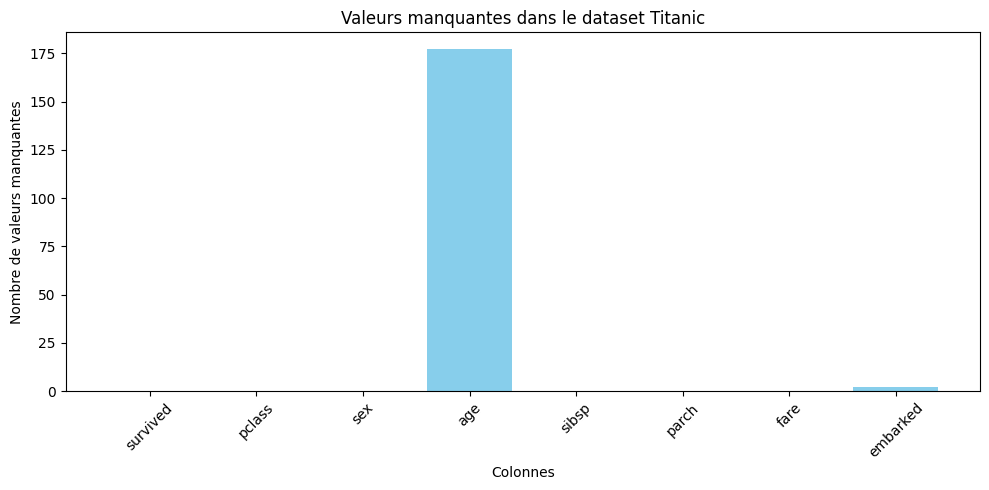

In [109]:
# TODO 1.5 : Bar chart of missing values

missing = df.isna().sum()

plt.figure(figsize=(10, 5))

plt.bar(missing.index, missing.values, color="skyblue")
# missing.index	Représente les noms des colonnes sur l'axe X.
# missing.values	Représente le nombre de valeurs manquantes sur l'axe Y

plt.title("Valeurs manquantes dans le dataset Titanic")
plt.xlabel("Colonnes")
plt.ylabel("Nombre de valeurs manquantes")

plt.xticks(rotation=45)
# Cette instruction permet de faire pivoter les étiquettes de l'axe X de 45 degrés.
plt.tight_layout()
# Ajuste les marges et les espacements du graphique
plt.show()

Interprétation du graphique :

•	age : 177 valeurs manquantes.

•	embarked : 2 valeurs manquantes.

•	Les 6 autres variables : aucune valeur manquante


# EXERCICE 2 :

In [110]:
# TODO 2.1 : Séparer les données en Train et Test 
from sklearn.model_selection import train_test_split
X = df.drop(columns="survived")
y = df["survived"]
# Séparer les variables explicatives (X) de la variable cible (y).
X_tr, X_te, y_tr, y_te = train_test_split( #Divise les données
    X, 
# DataFrame contient les variables explicatives 
      y, 
# Series Pandas contient la variable cible survived
    test_size=0.25,
    random_state=42,
    stratify=y
)

# tu peut faire "print(X), print(y), print(X_tr), print(X_te) .... pour voir plus de détaille les partie {brut, train, test}

À retenir :

- X et y : données avant la division.

- X_tr, y_tr : données d'entraînement.

- X_te, y_te : données de test.



In [111]:
# TODO 2.2 : Dimensions des ensembles et taux de survie 
# Afficher les dimensions des ensembles Train et Test.
print("Dimensions de X_tr :", X_tr.shape)
print("Dimensions de X_te :", X_te.shape)
print("Dimensions de y_tr :", y_tr.shape)
print("Dimensions de y_te :", y_te.shape)

# Calculer le taux de survie dans Train.
survival_train = y_tr.mean() * 100

# Calculer le taux de survie dans Test.
survival_test = y_te.mean() * 100

# Afficher les taux de survie avec deux chiffres après la virgule.
print(f"Taux de survie Train : {survival_train:.2f}%")
print(f"Taux de survie Test : {survival_test:.2f}%")

Dimensions de X_tr : (668, 7)
Dimensions de X_te : (223, 7)
Dimensions de y_tr : (668,)
Dimensions de y_te : (223,)
Taux de survie Train : 38.32%
Taux de survie Test : 38.57%


### Dimensions des ensembles Train et Test

| Variable | Dimensions attendues | Signification |
|---|---|---|
| `X_tr` | `(668, 7)` | 668 passagers, 7 caractéristiques |
| `X_te` | `(223, 7)` | 223 passagers, 7 caractéristiques |
| `y_tr` | `(668,)` | 668 étiquettes |
| `y_te` | `(223,)` | 223 étiquettes |

### TODO 2.3 : Vérifier que Train et Test sont disjoints 
### Objectif:
 vérifier qu'aucun passager du dataset Titanic n'appartient simultanément aux ensembles Train et Test.



In [112]:
assert set(X_tr.index).isdisjoint(set(X_te.index))
# Vérifier qu'aucun indice n'est commun aux ensembles Train et Test.
print("Vérification réussie : Train et Test sont disjoints.")
# Afficher un message si la vérification est réussie.


Vérification réussie : Train et Test sont disjoints.


Explication du code : 
### Explication du code du Question 2.3

| Instruction | Signification |
|---|---|
| `X_tr.index` | Récupère les indices des passagers de Train. |
| `X_te.index` | Récupère les indices des passagers de Test. |
| `.isdisjoint()` | Vérifie qu'aucun indice n'est commun aux deux ensembles. |
| `assert` | Vérifie que la condition est vraie. Sinon, déclenche une erreur `AssertionError`. |
 ### Exemple : 
Imaginons que nous avons :
- Train : indices {0, 1, 2, 3}
- Test : indices {4, 5, 6}
print(train_indices.isdisjoint(test_indices)) => on aura TRUE comme réponse puisqu'aucun indices du Train ne se trouve dans Test.

## <span style="color:red;"> Question 2.4 :</span>

Objectif

Comprendre le rôle de stratify=y dans la séparation des données en Train et Test.

Réponse et explication

Le paramètre stratify=y permet de conserver approximativement la même proportion de chaque classe dans les ensembles Train et Test.

Dans Titanic, la variable cible survived contient deux classes :

- 0 : passagers décédés.

- 1 : passagers survivants.

<b>À retenir :</b> la stratification est particulièrement importante lorsque les classes sont déséquilibrées. Elle limite le risque d'obtenir un ensemble Train ou Test contenant une proportion anormalement faible d'une classe.


## <span style="color:red;"> Exercice 3 : </span>

### TODO 3.1 : Survival rate by sex and pclass ----------------
### Objectif: calculer le taux de survie des passagers selon leur sexe et leur classe de voyage, puis représenter les résultats à l'aide de diagrammes en barres.


Taux de survie selon le sexe :
sex
female    75.213675
male      18.433180
Name: survived, dtype: float64
Taux de survie selon la classe :
pclass
1    66.037736
2    43.971631
3    24.184783
Name: survived, dtype: float64


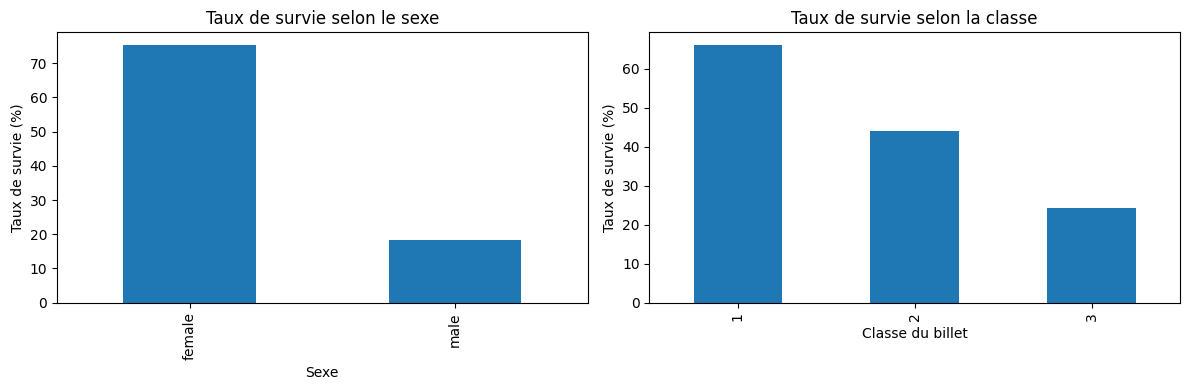

In [113]:
train = X_tr.assign(survived=y_tr)
# Réunir les variables explicatives et la variable cible dans un DataFrame.

survival_sex = train.groupby("sex")["survived"].mean() * 100
# Calculer le taux de survie selon le sexe des passagers.
survival_pclass = train.groupby("pclass")["survived"].mean() * 100
# Calculer le taux de survie selon la classe du billet.
print("Taux de survie selon le sexe :")
print(survival_sex)
# Afficher les résultats.
print("Taux de survie selon la classe :")
print(survival_pclass)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Créer deux graphiques côte à côte.
survival_sex.plot(kind="bar", ax=axes[0])
axes[0].set_title("Taux de survie selon le sexe")
axes[0].set_xlabel("Sexe")
axes[0].set_ylabel("Taux de survie (%)")
# Représenter le taux de survie selon le sexe.
survival_pclass.plot(kind="bar", ax=axes[1])
axes[1].set_title("Taux de survie selon la classe")
axes[1].set_xlabel("Classe du billet")
axes[1].set_ylabel("Taux de survie (%)")
# Représenter le taux de survie selon la classe.
plt.tight_layout()
plt.show()
# Ajuster l'espacement et afficher les graphiques.


	On va déterminer :
1.	Si les femmes présentent un taux de survie supérieur à celui des hommes.
2.	Si les passagers de première classe présentent un taux de survie supérieur à ceux de deuxième et troisième classes.
3.	Quelles catégories semblent les plus favorisées en matière de survie.
Taux de survie selon la classe

| Classe | Taux de survie |
|---|---|
| Première classe | 66,04 % ont survécu |
| Deuxième classe |	43,97 % ont survécu |
| Troisième classe | 24,18 % ont survécu |

#### Explication du code : Question 3.1

| Instruction | Signification |
|---|---|
| `X_tr.copy()` | Crée une copie des caractéristiques de Train. |
| `train["survived"] = y_tr` | Ajoute la variable cible à cette copie. |
| `groupby("sex")` | Regroupe les passagers selon leur sexe. |
| `groupby("pclass")` | Regroupe les passagers selon leur classe. |
| `["survived"].mean()` | Calcule la proportion de survivants dans chaque groupe. |

Pourquoi utiliser groupby() avec mean() :

groupby("sex") sépare les hommes et les femmes, tandis que mean() calcule leur proportion respective de survivants

Interpretation :
=> L'analyse exploratoire réalisée sur l'ensemble d'apprentissage montre que le taux de survie varie fortement selon le sexe et la classe du billet. Les femmes présentent un taux de survie de 75,21 %, contre seulement 18,43 % pour les hommes. Concernant la classe de voyage, le taux de survie diminue progressivement de 66,04 % en première classe à 24,18 % en troisième classe. Ces résultats indiquent que le sexe et la classe du billet sont deux variables fortement associées à la survie des passagers. Elles pourraient donc constituer des caractéristiques pertinentes pour un futur modèle de classification.

#### TODO 3.2 : Moyenne, médiane et asymétrie 
### Objectif : 	Calculer la moyenne et la médiane du prix du billet (fare) et de l'âge des passagers (age), puis mesurer l'asymétrie de la distribution des prix des billets à l'aide de .skew().


In [114]:
# TODO 3.2: Moyenne, médiane et asymétrie : mean and median of "fare" and "age"; skewness of "fare" (.skew())

fare_mean = train["fare"].mean()
# Calculer la moyenne des prix des billets.

fare_median = train["fare"].median()
# Calculer la médiane des prix des billets.

age_mean = train["age"].mean()
# Calculer la moyenne des âges.

age_median = train["age"].median()
# Calculer la médiane des âges.

fare_skew = train["fare"].skew()
# Mesurer l'asymétrie de la distribution des prix des billets.

# En Machine Learning, on calcule la moyenne et la médiane uniquement sur les données d'entraînement, pour éviter la fuite de données (Data Leakage).
# Puis on les utilise sur train, sans la recalculer.
print(f"Prix moyen du billet : {fare_mean:.2f}")
print(f"Prix médian du billet : {fare_median:.2f}")
print(f"Âge moyen : {age_mean:.2f}")
print(f"Âge médian : {age_median:.2f}")
print(f"Asymétrie de fare : {fare_skew:.2f}")
# Afficher les résultats avec deux décimales.

Prix moyen du billet : 31.18
Prix médian du billet : 13.86
Âge moyen : 29.93
Âge médian : 29.00
Asymétrie de fare : 4.85


Comprendre la moyenne et la médiane
Prenons cinq prix de billets :

10, 15, 20, 25, 200

<div align="center">
  <img src="moyenne.png" width="450">
  <p><i>Figure : Différence entre la moyenne et la médiane.</i></p>
</div>
 
=> skew() calcule l’asymétrie d’une distribution (Skewness : Asymétrie)

=> Elle permet de savoir si les valeurs sont réparties de manière symétrique ou si elles sont davantage étalées d’un côté.

<div align="center">
  <img src="Skew.png" width="450">
  <p><i>Figure : Différence entre la moyenne et la médiane.</i></p>
</div>

Après avoir calculé skew(), on peut utiliser cette règle pratique pour choisir entre la moyenne et la médiane :
### Interprétation du coefficient d'asymétrie — skew()

| **Valeur de skew()** | **Distribution** | **Choix conseillé** |
|---|---|---|
| `0` | Symétrique | Moyenne |
| Entre `-0,5` et `0,5` | Peu asymétrique | Moyenne |
| Entre `-1` et `-0,5` | Modérément asymétrique à gauche | Médiane possible |
| Entre `0,5` et `1` | Modérément asymétrique à droite | Médiane possible |
| Inférieure à `-1` ou supérieure à `1` | Fortement asymétrique | Médiane |

<div align="center">
  <img src="asymétrique.png" width="450">
  <p><i>Figure : Différence entre la moyenne et la médiane.</i></p>
</div>

À retenir :

skew() aide à choisir une méthode d'imputation :

•	Faible asymétrie → moyenne.
•	Forte asymétrie → médiane.

Ce choix doit être effectué à partir des données Train uniquement, pour éviter la fuite de données (Data Leakage).

=> 	Dans notre cas s kew = 4.85 = Très forte asymétrie positive = Médiane

<div align="center">
  <img src="skewness.png" width="450">
  <p><i>Figure : Différence entre la moyenne et la médiane.</i></p>
</div>

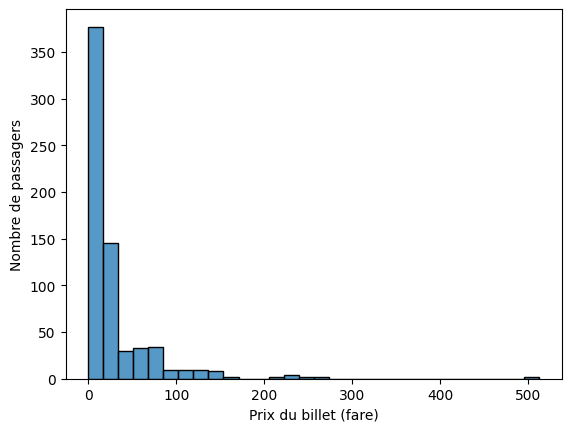

In [115]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(train["fare"], bins=30)
plt.xlabel("Prix du billet (fare)")
plt.ylabel("Nombre de passagers")
plt.show()


=> L'histogramme de la variable fare montre une distribution fortement asymétrique à droite, caractérisée par une concentration importante des passagers dans les faibles prix et une longue queue vers les prix élevés. Cette observation est cohérente avec le coefficient d'asymétrie positif (skew = 4.85). La présence de quelques billets particulièrement coûteux rend la moyenne sensible aux valeurs extrêmes. Par conséquent, la médiane constitue un choix pertinent pour l'imputation des valeurs manquantes.

=> Une question importante : remarques-tu que les barres les plus hautes sont à gauche, mais que nous parlons d'une asymétrie à droite ?

C'est parce que le sens de l'asymétrie est déterminé par la queue de la distribution, et non par l'endroit où se concentrent les données.


### TODO 3.3 : Matrice de corrélation et Heatmap
### Calculer la matrice de corrélation entre les variables age, fare, sibsp, parch et survived, puis représenter les résultats à l'aide d'une carte de chaleur (Heatmap). ;
Objectif :
Étudier les relations statistiques entre les variables numériques du Titanic afin de déterminer lesquelles sont les plus associées à la survie des passagers.


Matrice de corrélation :
               age      fare     sibsp     parch  survived
age       1.000000  0.088696 -0.307030 -0.188247 -0.095724
fare      0.088696  1.000000  0.127506  0.134647  0.295120
sibsp    -0.307030  0.127506  1.000000  0.370189 -0.011725
parch    -0.188247  0.134647  0.370189  1.000000  0.106585
survived -0.095724  0.295120 -0.011725  0.106585  1.000000


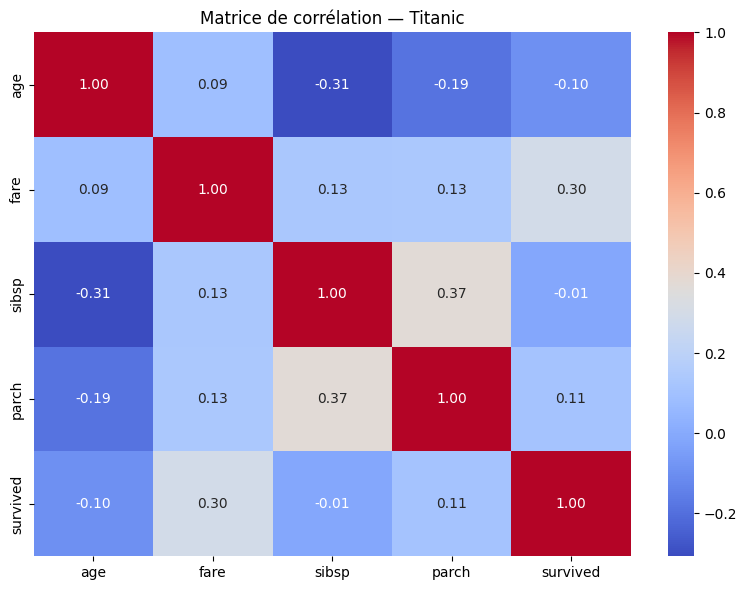

In [116]:
cols = ["age", "fare", "sibsp", "parch", "survived"]
#cols :Liste Python ;Contient les noms des variables à analyser.
#Sélectionner les colonnes nécessaires.
corr_matrix = train[cols].corr()
# Calculer la matrice de corrélation entre les variables.
#.corr() :Méthode Pandas :Calcule les coefficients de corrélation entre les variables numériques :Mesurer la force et le sens des relations linéaires.
print("Matrice de corrélation :")
print(corr_matrix)
# Afficher les coefficients de corrélation.
plt.figure(figsize=(8, 6))
# Créer une figure de 8 pouces de largeur et 6 pouces de hauteur.
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
# Représenter les corrélations avec une carte de chaleur(heatmap).
#  corr() : calcule les corrélations entre les variables numériques.
# sns.heatmap() : affiche ces corrélations sous forme de couleurs.
# annot=True : afficher les coefficients dans les cases.
# cmap="coolwarm" : utiliser une palette de couleurs.
# fmt=".2f" : afficher les coefficients avec deux décimales.
plt.title("Matrice de corrélation — Titanic")
# Ajouter un titre au graphique.
plt.tight_layout()
# Ajuster automatiquement les espacements.
plt.show()
# Afficher la Heatmap.



la corrélation (correlation en anglais) permet de mesurer la relation entre deux variables numériques.
1. Qu'est-ce qu'une corrélation ?
La corrélation indique si deux variables ont tendance à évoluer ensemble.

Prenons deux variables :
- age : l'âge des passagers.
- fare : le prix du billet.
Nous voulons savoir : lorsque l'âge augmente, est-ce que le prix du billet a tendance à augmenter, à diminuer ou à rester indépendant de l'âge ?

<div align="center">
  <img src="correlation.png" width="450">
</div>

. Ce qu'il faut retenir
- Le signe (+ ou −) indique le sens de la relation.
- La valeur absolue du coefficient indique la force de la relation linéaire.
- Une corrélation proche de 0 signifie qu'il n'existe pas de relation linéaire importante, mais une autre forme de relation peut exister.
- Corrélation ne signifie pas causalité : deux variables peuvent être associées sans que l'une soit la cause de l'autre.


### TODO 3.4 : Histogrammes de age et fare

Objectif: Tracer deux histogrammes pour visualiser la distribution de l'âge (age) et du prix des billets (fare) des passagers du Titanic.

=> Pour age, il faut exclure les valeurs manquantes à l'aide de dropna().


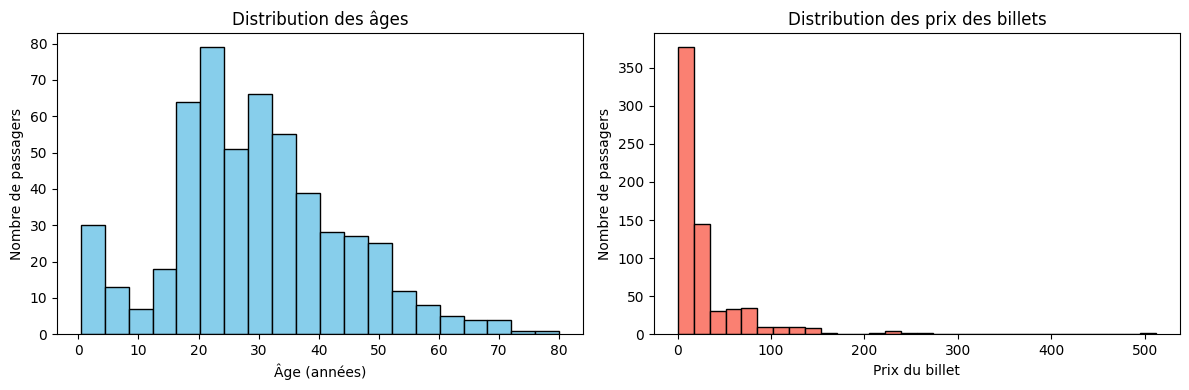

In [117]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Créer une figure contenant deux graphiques côte à côte.
axes[0].hist(train["age"].dropna(), bins=20, color="skyblue",
             edgecolor="black")
# Tracer l'histogramme des âges en ignorant les valeurs manquantes.
axes[0].set_title("Distribution des âges")
# Ajouter le titre du premier graphique.
axes[0].set_xlabel("Âge (années)")
# Définir le nom de l'axe horizontal.
axes[0].set_ylabel("Nombre de passagers")
# Définir le nom de l'axe vertical.

axes[1].hist(train["fare"], bins=30, color="salmon",  edgecolor="black")
# Tracer l'histogramme des prix des billets.
axes[1].set_title("Distribution des prix des billets")
# Ajouter le titre du deuxième graphique.
axes[1].set_xlabel("Prix du billet")
# Définir le nom de l'axe horizontal.
axes[1].set_ylabel("Nombre de passagers")
# Définir le nom de l'axe vertical.
plt.tight_layout()
# Ajuster automatiquement les espacements.
plt.show()
# Afficher les deux histogrammes.


### Comparaison des distributions de l'âge et du prix des billets

| **Caractéristique** | **Âge (`age`)** | **Prix du billet (`fare`)** |
|---|---|---|
| **Distribution** | Légèrement asymétrique à droite | Fortement asymétrique à droite |
| **Concentration** | Principalement entre 15 et 40 ans | Principalement entre 0 et 50 |
| **Valeurs extrêmes** | Quelques personnes âgées | Quelques billets très chers |
| **Indicateur central** | Moyenne ou médiane | Médiane privilégiée |

## <span style="color:red;"> EXERCICE 4 :</span>

### TODO 4.1 : la préparation des variables numériques
Nous devons préparer les données numériques et catégorielles :

- Remplacer les valeurs manquantes.

- Standardiser les variables numériques.

- Transformer les variables catégorielles en valeurs numériques.

- Éviter la fuite de données (Data Leakage).

Le principe essentiel : apprendre les paramètres de préparation uniquement sur Train, puis appliquer cette préparation à Test.




selon le document de Mr Nizar dans l'exercice 4 :

Question:
Avant le prétraitement, prévoyez le nombre de colonnes après transformation: 4 numériques, puis combien pour sex, embarked et pclass ?

Objectif
Comprendre comment le One-Hot Encoding modifie le nombre de colonnes après le prétraitement.

Réponse et explication:

Notre dataset Titanic contient 7 variables explicatives :

- 4 variables numériques : age, fare, sibsp, parch.

- 3 variables catégorielles : sex, embarked, pclass.

A. Variables numériques

Le StandardScaler modifie les valeurs, mais ne change pas le nombre de colonnes.

Résultat : 4 colonnes.

B. Variables catégorielles

Le OneHotEncoder crée une colonne pour chaque catégorie.

| Variable | Catégories | Colonnes créées |
|---|---|---:|
| `sex` | male, female | 2 |
| `embarked` | C, Q, S | 3 |
| `pclass` | 1, 2, 3 | 3 |
| **Total** | | **8** |

je prend l'exemple de la variable embarked:

| Passager | embarked_C | embarked_Q | embarked_S |
|---|---:|---:|---:|
| 1 | 0 | 0 | 1 |
| 2 | 1 | 0 | 0 |
| 3 | 0 | 1 | 0 |
| 4 | 0 | 0 | 1 |

Observe bien :
- C devient 1, 0, 0.
- Q devient 0, 1, 0.
- S devient 0, 0, 1.

=> on constate une colone devient 3 colonnes 

Conclusion à tirer:

Après le prétraitement, le nombre de colonnes passe de 7 à 12, car le One-Hot Encoding transforme les trois variables catégorielles en huit colonnes binaires.

À retenir : l'imputation et la standardisation conservent ici le nombre de colonnes, tandis que le One-Hot Encoding l'augmente.

In [118]:
#TODO : 4.1

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    # Remplacer les valeurs manquantes par la médiane de chaque colonne.

    ("scaler", StandardScaler())
    # Standardiser les variables numériques.
])

### Ce pipeline réalise deux opérations successives :
### Explication du pipeline numérique — TODO 4.1

| **Instruction** | **Rôle** |
|---|---|
| `Pipeline()` | Regroupe plusieurs opérations exécutées dans un ordre précis. |
| `SimpleImputer(strategy="median")` | Remplace les valeurs manquantes par la médiane calculée sur Train. |
| `StandardScaler()` | Standardise les variables pour obtenir une moyenne de 0 et un écart-type de 1 sur Train. |

A. Pipeline()
Un pipeline est une succession d'opérations exécutées automatiquement dans un ordre précis.

<div align="center">
  <img src="pipline.png" width="450">
</div>

B. SimpleImputer(strategy="median")
Dans Titanic, certains passagers n'ont pas d'âge renseigné.

Par exemple :

|Passager |	Âge avant imputation |
|---|---|
|1 | 20 |
|2 | 25 |
|3 | NaN |
|4 | 30 |
|5 | 80 |

Les âges connus sont : 20, 25, 30, 80

## La médiane est : 25 + 30 / 2 = 27.5

L'imputation remplace donc NaN par 27,5

### Âges des passagers après imputation par la médiane

| **Passager** | **Âge après imputation** |
|---|---|
| 1 | 20 |
| 2 | 25 |
| 3 | 27,5 |
| 4 | 30 |
| 5 | 80 |

Pourquoi la médiane et non la moyenne ?

Parce que la médiane est moins sensible aux valeurs extrêmes.

Dans cet exemple, l'âge de 80 ans augmente la moyenne, tandis que la médiane reste à 27,5.

C. StandardScaler()
Après l'imputation, nous standardisons les valeurs.

La formule est :

### Formule de standardisation

$$
z = \frac{x-\mu}{\sigma}
$$

Avec :

- $x$ : valeur d'origine.
- $\mu$ : moyenne calculée sur Train.
- $\sigma$ : écart-type calculé sur Train.
- $z$ : valeur standardisée.

Prenons un exemple simple :
- Âge d'un passager : 40 ans.
- Moyenne des âges : 30 ans.
- Écart-type : 10 ans.
Alors :
$$
z = \frac{x-\mu}{\sigma}
  = \frac{40-30}{10}
  = 1
$$

**Interprétation :**

La valeur standardisée $z = 1$ signifie que l'âge du passager se situe **un écart-type au-dessus de la moyenne**.

Après standardisation, chaque variable numérique de Train a généralement :

- Une moyenne proche de 0.
- Un écart-type proche de 1.

Pourquoi standardiser ?
Dans Titanic, les variables n'utilisent pas la même échelle :
- age : de 0 à environ 80 ans.
- fare : de 0 à plus de 500.
- sibsp : généralement de 0 à quelques unités.
- parch : généralement de 0 à quelques unités.
Sans standardisation, certaines méthodes sensibles aux échelles, comme kNN ou la régression logistique régularisée, peuvent être influencées par les différences d'amplitude entre les variables.

La standardisation rend ces variables plus comparables numériquement.

4. Attention à la fuite de données

Lorsque nous écrivons :
X_tr_prep = pre.fit_transform(X_tr)

Le pipeline apprend sur Train :

- Les médianes utilisées pour remplacer les valeurs manquantes.
- Les moyennes et écarts-types nécessaires à la standardisation.

Puis :

X_te_prep = pre.transform(X_te)

Il applique ces mêmes paramètres à Test.

On ne recalcule jamais les médianes, les moyennes et les écarts-types sur Test dans ce protocole.

### TODO 4.2 : le pipeline des variables catégorielles

Objectif du TODO 4.2
Nous voulons préparer les variables catégorielles pour qu'elles puissent être utilisées par un modèle de Machine Learning.

 SimpleImputer(most_frequent) -> OneHotEncoder(handle_unknown="ignore")


In [119]:
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    # Remplacer les valeurs manquantes par la catégorie la plus fréquente.

    ("encoder", OneHotEncoder(handle_unknown="ignore"))
    # Transformer les catégories en colonnes binaires (0 et 1).
    # Ignorer les catégories inconnues rencontrées lors de la transformation.
])

nous avons trois variables catégorielles :

categorical = ["sex", "embarked", "pclass"]

### Variables catégorielles du dataset Titanic

| **Variable** | **Signification** | **Valeurs possibles** |
|---|---|---|
| `sex` | Sexe du passager | male, female |
| `embarked` | Port d'embarquement | C, Q, S |
| `pclass` | Classe du billet | 1, 2, 3 |

Étape 1 — Pipeline()

Étape 2 — SimpleImputer(strategy="most_frequent")

Étape 3 — OneHotEncoder()

Étape 4 — handle_unknown="ignore"

À retenir :

Le pipeline catégoriel effectue deux transformations dans cet ordre :

1. Imputation → compléter les valeurs manquantes.
2. Encodage → transformer les catégories en nombres.


### TODO 4.3 : ColumnTransformer.

## Objectif

Combiner les deux pipelines que nous avons créés :

- numeric_pipe : imputation par la médiane + standardisation.
- categorical_pipe : imputation par la catégorie la plus fréquente + One-Hot Encoding.

In [120]:
# TODO 4.3: ColumnTransformer(..., sparse_threshold=0)
# ColumnTransformer();Applique différents traitements à différents groupes de colonnes.

from sklearn.compose import ColumnTransformer

# Définir les colonnes numériques
numeric = ["age", "fare", "sibsp", "parch"]

# Définir les colonnes catégorielles
categorical = ["sex", "embarked", "pclass"]

# Combiner les deux pipelines
pre = ColumnTransformer([
# pre = ColumnTransformer(...) ne transforme pas encore les données => Elle définit seulement les opérations à effectuer
    ("num", numeric_pipe, numeric),
    # numeric_pipe: Pipeline appliqué aux variables numériques
    ("cat", categorical_pipe, categorical)
    # categorical: Liste des colonnes : sex, embarked, pclass
], sparse_threshold=0)
    # sparse_threshold=0 : Force une sortie dense (tableau classique), plutôt qu'une matrice creuse

print("ColumnTransformer créé avec succès !")

ColumnTransformer créé avec succès !


In [121]:
# TODO 4.4: fit on TRAIN

X_tr_prep = pre.fit_transform(X_tr)
# fit : apprendre les médianes, modes, moyennes,
# écarts-types et catégories à partir de TRAIN.
# transform : appliquer les transformations à TRAIN.

In [122]:
# TODO 4.5: apply to TEST
X_te_prep = pre.transform(X_te)
# Appliquer au TEST les transformations apprises sur TRAIN.
# Ne jamais appeler fit ou fit_transform sur TEST.

In [123]:
# TODO 4.6: print shapes and pre.get_feature_names_out()
print("Dimensions de TRAIN après prétraitement :")
print(X_tr_prep.shape)
# Afficher le nombre de lignes et de colonnes de TRAIN.

print("\nDimensions de TEST après prétraitement :")
print(X_te_prep.shape)
# Afficher le nombre de lignes et de colonnes de TEST.

print("\nNoms des variables après prétraitement :")
print(pre.get_feature_names_out())
# Afficher les noms des colonnes numériques et encodées.

Dimensions de TRAIN après prétraitement :
(668, 12)

Dimensions de TEST après prétraitement :
(223, 12)

Noms des variables après prétraitement :
['num__age' 'num__fare' 'num__sibsp' 'num__parch' 'cat__sex_female'
 'cat__sex_male' 'cat__embarked_C' 'cat__embarked_Q' 'cat__embarked_S'
 'cat__pclass_1' 'cat__pclass_2' 'cat__pclass_3']


Nous avions terminé l'exercice 4, dans lequel nous avons construit un Pipeline avec :

- SimpleImputer : remplacer les valeurs manquantes.

- StandardScaler : standardiser les variables numériques.

- OneHotEncoder : encoder les variables catégorielles.

- ColumnTransformer : combiner les transformations.

## Question 4.7 — Pourquoi encoder sex et embarked en One-Hot plutôt qu'avec des codes entiers (0, 1, 2) ?

# Objectif

Comprendre pourquoi on utilise le One-Hot Encoding pour transformer les variables catégorielles en valeurs numériques.

# Réponse et explication

Les variables sex et embarked sont des variables catégorielles nominales, c'est-à-dire sans ordre naturel.

Prenons l'exemple de embarked en One-Hot Encoding :

### Exemple de One-Hot Encoding de la variable `embarked`

| Port | embarked_C | embarked_Q | embarked_S |
|---|---:|---:|---:|
| C | 1 | 0 | 0 |
| Q | 0 | 1 | 0 |
| S | 0 | 0 | 1 |

Chaque catégorie possède sa propre colonne binaire.

Ainsi, aucune catégorie ne reçoit un rang numérique artificiel.

C = [1,0,0]

    Q = [0,1,0]

    S = [0,0,1]

Attention ce n'est pas un code binaire 100 = 4 non !!
Conclusion à tirer

Le One-Hot Encoding permet de transformer les variables catégorielles nominales en colonnes binaires (0 ou 1), sans créer de relation d'ordre artificielle entre les catégories.

À retenir : 
pour les variables nominales comme sex et embarked, le One-Hot Encoding est généralement préférable à un encodage par entiers pour les modèles sensibles à l'ordre ou aux distances.




### Question 4.8	Ici,pclass	est	aussi	encodée	en	one-hot.	Donnez	un	argument	pour	ce	choix	et	un	argument pour	conserver	pclass	telle	quelle	(variable	ordinale).

Objectif:

Comprendre la différence entre une variable nominale et une variable ordinale, et savoir choisir une méthode d'encodage adaptée.

Réponse et explication

Dans Titanic, pclass représente la classe du billet :

- 1 : première classe.

- 2 : deuxième classe.

- 3 : troisième classe.

Contrairement à embarked, cette variable possède un ordre naturel.

A. Pourquoi utiliser One-Hot Encoding ?

Le One-Hot Encoding transforme chaque classe en une colonne indépendante.

| pclass | pclass_1 | pclass_2 | pclass_3 |
|---|---:|---:|---:|
| 1 | 1 | 0 | 0 |
| 2 | 0 | 1 | 0 |
| 3 | 0 | 0 | 1 |

Avantage : le modèle peut apprendre un effet différent pour chaque classe, sans supposer que les écarts entre les classes 1, 2 et 3 sont identiques.

B. Pourquoi conserver pclass comme variable ordinale ?

Nous pouvons également conserver les valeurs :

| pclass | Signification |
|---|---|
| 1 | Première classe |
| 2 | Deuxième classe |
| 3 | Troisième classe |

Avantages :

- L'ordre des classes est conservé.

- Une seule colonne est nécessaire au lieu de trois.

- Le prétraitement est plus simple.

Attention : 

certains modèles pourraient considérer que la différence entre les classes 1 et 2 est identique à celle entre les classes 2 et 3, ce qui n'est pas nécessairement vrai.

Conclusion à tirer

Le One-Hot Encoding permet de traiter chaque classe indépendamment, tandis que l'encodage ordinal conserve l'ordre naturel des classes et réduit le nombre de colonnes.

À retenir : le choix dépend de la nature de la variable et de l'algorithme utilisé.

## Question 4.9 — Contre quoi protège `handle_unknown="ignore"` ?

# Objectif

Comprendre comment `handle_unknown="ignore"` permet de gérer les nouvelles catégories rencontrées dans le Test.

# Réponse et explication

Le paramètre `handle_unknown="ignore"` permet d'éviter une erreur lorsqu'une catégorie présente dans le Test n'existait pas dans le Train.

Exemple :

Supposons que la variable `embarked` contienne :

- Train : C, Q, S.
- Test : C, Q, S, X.

La catégorie `X` est inconnue, car elle n'a jamais été rencontrée pendant l'apprentissage.

Sans `handle_unknown="ignore"` :

Le programme déclenche une erreur lors de la transformation du Test.

Avec `handle_unknown="ignore"` :

La catégorie inconnue est représentée par des zéros dans toutes les colonnes correspondantes.

| Port        | embarked_C | embarked_Q | embarked_S |
| ----------- | ---------- | ---------- | ---------- |
| C           | 1          | 0          | 0          |
| Q           | 0          | 1          | 0          |
| S           | 0          | 0          | 1          |
| X (inconnu) | 0          | 0          | 0          |

Le programme peut ainsi continuer sans erreur.


# Conclusion à tirer

> `handle_unknown="ignore"` protège contre les erreurs provoquées par l'apparition de nouvelles catégories dans le Test. Ces catégories sont encodées par des zéros, sans modifier le nombre de colonnes.

À retenir : 
ce paramètre évite une erreur d'encodage, mais ne signifie pas que le modèle a appris à reconnaître la nouvelle catégorie.

Remarque : `X` est un exemple fictif. Dans notre dataset Titanic, les ports habituels sont C, Q et S.

## Exercice 4 — Point de contrôle

### Question

Les matrices Train et Test ont-elles le même nombre de colonnes après le prétraitement ? Ce nombre correspond-il à votre prédiction ?

Objectif

Vérifier que le `ColumnTransformer` applique les mêmes transformations au Train et au Test, afin d'obtenir le même nombre de caractéristiques.

Réponse et explication

| Ensemble | Nombre de lignes | Nombre de colonnes |
| -------- | ---------------- | ------------------ |
| Train    | 668              | 12                 |
| Test     | 223              | 12                 |

Pourquoi 12 colonnes ?

- 4 colonnes numériques : `age`, `fare`, `sibsp`, `parch`.
- 2 colonnes pour `sex`.
- 3 colonnes pour `embarked`.
- 3 colonnes pour `pclass`.

    4+2+3+3 = 12

Pourquoi le Train et le Test possèdent-ils les mêmes colonnes ?

Parce que :

```
X_tr_prep = pre.fit_transform(X_tr)

X_te_prep = pre.transform(X_te)
```

- `fit_transform(X_tr)` apprend les paramètres et les catégories sur le Train, puis le transforme.
- `transform(X_te)` applique au Test les transformations déjà apprises, sans créer de nouvelles colonnes.

# Conclusion à tirer

> Les matrices Train et Test possèdent toutes les deux 12 colonnes après le prétraitement. Cela confirme que les mêmes caractéristiques sont utilisées pour l'apprentissage et l'évaluation du modèle.

À retenir :
 le nombre de lignes peut être différent entre Train et Test, mais leurs caractéristiques doivent être compatibles.


### Exercice 5 : Contrôles et diagnostic du prétraitement.



Question a. 5.1 — Vérifier l'absence de valeurs manquantes

Objectif : vérifier qu'après le prétraitement, les matrices Train et Test ne contiennent plus de valeurs NaN.

 => Vérifier que l'imputation réalisée dans l'exercice 4 avec SimpleImputer
    a correctement remplacé les valeurs manquantes dans Train et Test.

In [124]:
# Question 5a TODO 5.1 ; no NaN left in X_tr_prep and X_te_prep

import numpy as np

# Vérifier l'absence de NaN dans Train et Test
assert not np.isnan(X_tr_prep).any()
assert not np.isnan(X_te_prep).any()
# np.isnan() recherche les valeurs manquantes
# assert	Vérifie qu'une condition est vraie ; sinon, déclenche une erreur
# not   	Inverse le résultat booléen
# .any()	Retourne True si au moins une valeur est NaN

print("Vérification réussie : aucune valeur NaN dans Train et Test.")

Vérification réussie : aucune valeur NaN dans Train et Test.


Interprétation :

Si les deux assertions sont satisfaites, Python affiche :
Vérification réussie : aucune valeur NaN dans Train et Test

Cela signifie que :

- X_tr_prep ne contient aucune valeur NaN.

- X_te_prep ne contient aucune valeur NaN.

- Le prétraitement a correctement traité les valeurs manquantes détectées par ce contrôle.

En cas d'échec : Python déclenche une AssertionError, ce qui indique qu'au moins une des matrices contient encore des valeurs manquantes.

Si une valeur NaN existe encore, assert déclenche une AssertionError.

Conclusion à tirer:

Les matrices Train et Test ne contiennent plus de valeurs manquantes après le prétraitement

À retenir :

Une assertion est un contrôle automatique qui permet de vérifier qu'une condition est respectée.

<h3 style="color:#9333EA;">
<u><b>Question 5.2 — Vérification de la standardisation</b></u>
</h3>

<p style="color:#9333EA;">
Vérifier que les quatre premières colonnes numériques de
<code>X_tr_prep</code> ont une moyenne proche de 0
et un écart-type proche de 1.
</p>

<div style="color:#2563EB;">

<h3><u>Objectif :</u></h3>

<p>
Vérifier que <code>StandardScaler</code> a correctement
standardisé les quatre variables numériques du Train.
</p>

<table>
    <thead>
        <tr>
            <th>Variable</th>
            <th>Signification</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><code>age</code></td>
            <td>Âge du passager</td>
        </tr>
        <tr>
            <td><code>fare</code></td>
            <td>Prix du billet</td>
        </tr>
        <tr>
            <td><code>sibsp</code></td>
            <td>Nombre de frères, sœurs ou conjoints à bord</td>
        </tr>
        <tr>
            <td><code>parch</code></td>
            <td>Nombre de parents ou enfants à bord</td>
        </tr>
    </tbody>
</table>

<p><b>Formule de standardisation :</b></p>

</div>
$$
z = \frac{x-\mu}{\sigma}
$$
<div style="color:#EA580C;">

<p><b><u>À retenir :</u></b></p>

<ul>
    <li><b>x :</b> valeur initiale.</li>
    <li><b>μ :</b> moyenne du Train.</li>
    <li><b>σ :</b> écart-type du Train.</li>
    <li><b>z :</b> valeur standardisée.</li>
</ul>

<p>
<b>Résultat attendu :</b> après standardisation,
chaque variable numérique non constante du Train possède
une moyenne ≈ 0 et un écart-type ≈ 1.
</p>

</div>

In [125]:
# Exercice 5a — TODO 5.2
# Vérifier la standardisation des 4 variables numériques du Train

assert np.allclose(X_tr_prep[:, :4].mean(axis=0), 0, atol=1e-7)

# np.allclose()	Vérifie si les valeurs calculées sont proches des valeurs attendues
# [:, :4]	Sélectionne toutes les lignes et les quatre premières colonnes.
# mean(axis=0)	Calcule la moyenne de chaque colonne.
# atol=1e-7	Accepte une très petite différence numérique.

assert np.allclose(X_tr_prep[:, :4].std(axis=0), 1, atol=1e-7)

print("Vérification réussie : moyenne ≈ 0 et écart-type ≈ 1.")

Vérification réussie : moyenne ≈ 0 et écart-type ≈ 1.


<div style="color:#2563EB;">

<h3><u><b>Interprétation du résultat :</b></u></h3>

<p>
Les deux assertions sont exécutées sans erreur, ce qui confirme que :
</p>

<ul>
    <li>Les quatre variables numériques du Train ont une <b>moyenne ≈ 0</b>.</li>
    <li>Leur <b>écart-type ≈ 1</b>.</li>
    <li>La standardisation avec <code>StandardScaler</code> est correcte.</li>
</ul>

</div>

<div style="color:#EA580C;">

<h3><u><b>Conclusion à tirer :</b></u></h3>

<p>
Le <code>StandardScaler</code> a correctement standardisé les
quatre variables numériques du Train. Elles sont désormais
<b>centrées autour de 0</b> avec un <b>écart-type proche de 1</b>,
ce qui permet de les placer sur des échelles comparables.
</p>

</div>

Question 5.3 : Moyennes et écarts-types du Test

TODO 5.3 : Afficher les moyennes et les écarts-types des quatre colonnes numériques de X_te_prep.

Objectif:

Examiner les caractéristiques statistiques des quatre variables numériques du jeu de Test après leur standardisation.

Contrairement au Train, les moyennes du Test ne doivent pas nécessairement être égales à 0 et les écarts-types ne doivent pas nécessairement être égaux à 1.

Pourquoi ?

 Parce que StandardScaler utilise les paramètres appris sur Train pour transformer Test.

In [126]:
# Exercice 5a — TODO 5.3

# Calculer les moyennes des 4 colonnes numériques du Test

test_means = X_te_prep[:, :4].mean(axis=0)
# X_te_prep	Matrice Test après prétraitement
# .mean(axis=0)	Calcule la moyenne de chaque colonne numérique
# test_means	Stocke les quatre moyennes obtenues.


# Calculer les écarts-types des 4 colonnes numériques du Test
test_stds = X_te_prep[:, :4].std(axis=0)
# .std(axis=0)	Calcule l'écart-type de chaque colonne numérique
# test_stds	Stocke les quatre écarts-types obtenus

# Afficher les résultats
print("Moyennes du Test :", test_means)
print("Écarts-types du Test :", test_stds)

Moyennes du Test : [-0.05826086  0.08650669  0.23580864  0.02806194]
Écarts-types du Test : [1.01202214 1.17529784 1.35263804 0.86465955]


Les quatre variables sont, dans l'ordre :

1. age

2. fare

3. sibsp

4. parch

<div style="color:#2563EB;">

<h3><u><b>Interprétation du résultat :</b></u></h3>

<p>
Les moyennes des quatre variables numériques du Test peuvent
être différentes de 0 et leurs écarts-types différents de 1.
</p>

<p>
Cela est normal, car <code>StandardScaler</code> utilise
la moyenne et l'écart-type calculés uniquement sur
<b>Train</b> pour transformer les données du <b>Test</b>.
</p>

</div>

<div style="color:#EA580C;">

<h3><u><b>Conclusion à tirer :</b></u></h3>

<p>
Les données du Test sont standardisées avec les paramètres
appris sur Train. Le Test ne participe pas au calcul
de ces paramètres, ce qui permet d'éviter une
<b>fuite de données (Data Leakage)</b> lors de cette étape.
</p>

</div>


# Exercice 5b — TODO 5.4

scaler = StandardScaler()

fare_scaled = scaler.fit_transform(X[["fare"]])

fs_tr, fs_te = train_test_split(
    fare_scaled,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("mean used by the scaler:", scaler.mean_)

<h3 style="color:#9333EA;">
<u>Question 5.4 — Identifier une fuite de données</u>

</h3>

<div style="color:#2563EB;">

<p><b><u>Objectif :</u></b></p>

<p>
Comprendre pourquoi la standardisation doit être effectuée
après la séparation Train/Test afin d'éviter une fuite de données.
</p>

</div>

<div style="color:#16A34A;">

<p><b><u>Réponse — Identification de l'erreur :</u></b></p>

<p>L'erreur se trouve dans :</p>

<p><code>fare_scaled = scaler.fit_transform(X[["fare"]])</code></p>

<p>
Cette instruction calcule la moyenne et l'écart-type
sur toutes les données (Train + Test) avant leur séparation.
</p>

Pourquoi ?

- X contient toutes les données (Train + Test).

- fit_transform() calcule la moyenne et l'écart-type sur toutes ces données.

- La séparation train_test_split() est effectuée trop tard.

Cela provoque une fuite de données (Data Leakage), car les informations du Test influencent le prétraitement du Train.
</div>

<div style="color:#2563EB;">

<p><b><u>Interprétation :</u></b></p>

<p>
Le scaler utilise des informations du Test pour préparer le Train.
Cela provoque une <b>fuite de données (Data Leakage)</b>.
</p>

</div>

<div style="color:#EA580C;">

<p><b><u>Conclusion à tirer :</u></b></p>

<p>
Toujours séparer les données avant la standardisation :
</p>

<ul>
    <li><b>Train :</b> <code>fit_transform()</code>.</li>
    <li><b>Test :</b> <code>transform()</code> uniquement.</li>
</ul>

</div>

5.5 : Corriger la fuite de données et comparer les moyennes

TODO 5.5 : Écrire la version corrigée du code et comparer les deux valeurs de scaler.mean_.

Objectif

Corriger la fuite de données en effectuant la séparation Train/Test avant la standardisation, puis comparer :

- La moyenne incorrecte : calculée sur toutes les données.

- La moyenne correcte : calculée uniquement sur Train.

In [127]:
# Exercice 5b — TODO 5.5

# Calculer la moyenne incorrecte (Train + Test)
scaler_wrong = StandardScaler()
scaler_wrong.fit(X[["fare"]])

# Séparer les données avant la standardisation
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Créer un nouveau StandardScaler
scaler_correct = StandardScaler()

# Apprendre les paramètres uniquement sur Train
fare_train_scaled = scaler_correct.fit_transform(X_train[["fare"]])

# Transformer Test avec les paramètres appris sur Train
fare_test_scaled = scaler_correct.transform(X_test[["fare"]])

# Comparer les moyennes
print("Moyenne incorrecte :", scaler_wrong.mean_)
print("Moyenne correcte :", scaler_correct.mean_)

Moyenne incorrecte : [32.20420797]
Moyenne correcte : [31.17746946]


<h3 style="color:#9333EA;">
<u><b>Question 5.5 — Correction de la fuite de données</b></u>
</h3>

<p style="color:#9333EA;">
Écrire la version corrigée du code et comparer les deux
valeurs de <code>scaler.mean_</code>.
</p>

<div style="color:#2563EB;">

<p><b><u>Objectif :</u></b></p>

<p>
Effectuer la séparation Train/Test avant la standardisation
et comparer la moyenne calculée sur toutes les données
avec celle calculée uniquement sur Train.
</p>

</div>

<div style="color:#16A34A;">

<p><b><u>Réponse :</u></b></p>

<p>
La méthode correcte consiste à séparer les données,
puis à appliquer <code>fit_transform()</code> sur Train
et <code>transform()</code> sur Test.
</p>

</div>

<div style="color:#2563EB;">

<p><b><u>Interprétation du résultat :</u></b></p>

Le programme affiche deux moyennes :

Moyenne incorrecte : elle utilise toutes les observations, y compris celles du Test.

Moyenne correcte : elle utilise uniquement les observations du Train.

<p>
La moyenne incorrecte est calculée sur
<b>Train + Test</b>, tandis que la moyenne correcte
est calculée uniquement sur <b>Train</b>.
</p>

<p>
Les deux moyennes peuvent être différentes,
car elles ne sont pas calculées sur les mêmes observations.
</p>

</div>

<div style="color:#EA580C;">

<p><b><u>Conclusion à tirer :</u></b></p>

<p>
Il faut toujours séparer Train et Test avant d'apprendre
les paramètres du prétraitement.
Le Test ne doit jamais intervenir dans leur calcul,
afin d'éviter une <b>fuite de données (Data Leakage)</b>.
</p>

</div>

# 7.	Extensions	facultatives	(hors	temps	obligatoire)


 Question : E1 

Appliquez np.log1p() à la variable fare, puis comparez son asymétrie (skewness) et son histogramme avant et après transformation.

Objectif
Comprendre comment une transformation logarithmique permet de réduire l'asymétrie d'une distribution et l'influence visuelle des valeurs extrêmes.

Explication

Dans notre TP Titanic, la variable fare représente le prix du billet.

Nous avons déjà constaté dans le TODO 3.2 que :

- La majorité des passagers ont payé des billets relativement peu coûteux.

- Quelques passagers ont payé des billets très chers.

- Le coefficient d'asymétrie est fortement positif (environ 4,85).

La distribution possède donc une longue queue vers la droite.

Pourquoi utiliser np.log1p() ?

Cette fonction calcule :

log(1+x)


Skew avant : 4.845059411519961
Skew après : 0.33151660810228295


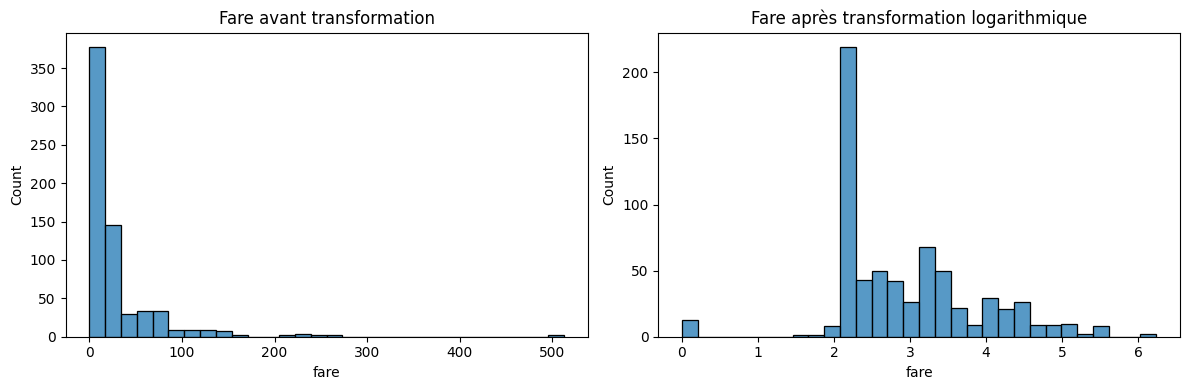

In [128]:
# Extension E1 — Transformation logarithmique de fare

# Utiliser uniquement les données Train
fare_original = train["fare"]
fare_log = np.log1p(fare_original)

# Calculer l'asymétrie
print("Skew avant :", fare_original.skew())
print("Skew après :", fare_log.skew())

# Comparer les histogrammes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(fare_original, bins=30, ax=axes[0])
axes[0].set_title("Fare avant transformation")

sns.histplot(fare_log, bins=30, ax=axes[1])
axes[1].set_title("Fare après transformation logarithmique")

plt.tight_layout()
plt.show()

Interprétation des résultats

| Avant transformation | Après transformation |
|---|---|
| Forte asymétrie à droite | Asymétrie généralement réduite |
| Valeurs élevées très éloignées | Valeurs élevées compressées |
| Distribution très étalée | Distribution plus resserrée |

Attention : 

la transformation logarithmique ne garantit pas une distribution parfaitement symétrique ou normale.

Conclusion à tirer

La transformation logarithmique np.log1p() réduit l'écart entre les valeurs faibles et élevées de fare. Elle permet généralement de diminuer l'asymétrie positive de la distribution.

### E2	—	Indicateur	de	valeur	manquante.	Comparez	le	taux	de	survie	des	passagers	dont	l’âge est	manquant	avec	celui	des	autres.	Testez	ensuite	SimpleImputer(strategy="median"add_indicator=True).	Combien	de	colonnes	obtenez-vous	?

Objectif

Comprendre comment les valeurs manquantes peuvent elles-mêmes apporter une information utile à un modèle de Machine Learning.

Dans notre dataset Titanic, certains passagers n'ont pas d'âge renseigné (NaN).

Nous souhaitons savoir si le taux de survie est différent selon que l'âge est renseigné ou manquant.

Pour cela, nous créons un indicateur binaire :

- 0 : l'âge est renseigné.

- 1 : l'âge est manquant.

In [93]:
SimpleImputer(strategy="median", add_indicator=True)

,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",True
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False


Conclusion à tirer

SimpleImputer(strategy="median", add_indicator=True) remplace les âges manquants par la médiane et ajoute une colonne binaire pour identifier les valeurs initialement manquantes.

À retenir : 

add_indicator=True permet au modèle de conserver une information potentiellement utile : le fait qu'une valeur était absente avant l'imputation.

In [ ]:
#Comparer les taux de survie; À exécuter après la création de train dans l'exercice 3
# Extension E2 — Indicateur de valeur manquante

# Créer un indicateur de valeur manquante
train["age_missing"] = train["age"].isna().astype(int)

# Comparer les taux de survie
survival_by_missing = train.groupby("age_missing")["survived"].mean()

print("Taux de survie selon la disponibilité de l'âge :")
print((survival_by_missing * 100).round(2))

Taux de survie selon la disponibilité de l'âge :
age_missing
0    40.97
1    27.48
Name: survived, dtype: float64


Interprétation :

- age_missing = 0 : taux de survie des passagers dont l'âge est connu.

- age_missing = 1 : taux de survie des passagers dont l'âge est inconnu.

Si les deux taux sont différents, cela suggère que l'absence d'âge peut être associée à la survie.

In [130]:
from sklearn.impute import SimpleImputer

# Sélectionner uniquement la variable age du Train
X_age = X_tr[["age"]]

# Imputation avec indicateur
imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)

X_age_imputed = imputer.fit_transform(X_age)

print("Dimensions avant :", X_age.shape)
print("Dimensions après :", X_age_imputed.shape)

Dimensions avant : (668, 1)
Dimensions après : (668, 2)


Pourquoi deux colonnes ?

missingindicator_age	Indique si l'âge était initialement manquant (1) ou non (0)

Conclusion à tirer

SimpleImputer(strategy="median", add_indicator=True) remplace les valeurs manquantes par la médiane et ajoute une colonne binaire indiquant quelles valeurs étaient initialement manquantes.

À retenir : 

l'indicateur permet de conserver l'information sur l'absence d'une valeur, même après son imputation.

À retenir :

L'imputation est une technique de prétraitement qui consiste à remplacer les valeurs manquantes par des valeurs estimées, comme la moyenne, la médiane ou le mode.

| Méthode | Principe |
|---|---|
| Moyenne (`mean`) | Remplacer par la moyenne |
| Médiane (`median`) | Remplacer par la médiane |
| Mode (`most_frequent`) | Remplacer par la valeur la plus fréquente |
| Constante (`constant`) | Remplacer par une valeur définie |

Extension E3 — Artefact d'imputation

Question

Combien d'âges sont imputés dans l'ensemble d'apprentissage (Train) ? Tracez l'histogramme de age après imputation et commentez le résultat.

Objectif

- Déterminer le nombre d'âges manquants remplacés dans le Train.

- Visualiser la distribution des âges après l'imputation.

- Comprendre l'effet de l'imputation par la médiane sur la distribution.


In [ ]:
# Compter Nombre d'âges imputés dans Train

n_missing = X_tr["age"].isna().sum()

print("Nombre d'âges imputés :", n_missing)
print("Nombre total de passagers dans Train :", len(X_tr))

Nombre d'âges imputés : 131
Nombre total de passagers dans Train : 668


Interprétation :

Le nombre affiché correspond aux passagers du Train dont l'âge était initialement manquant.

Chaque valeur NaN sera remplacée par la médiane calculée sur Train

Médiane utilisée : 29.0


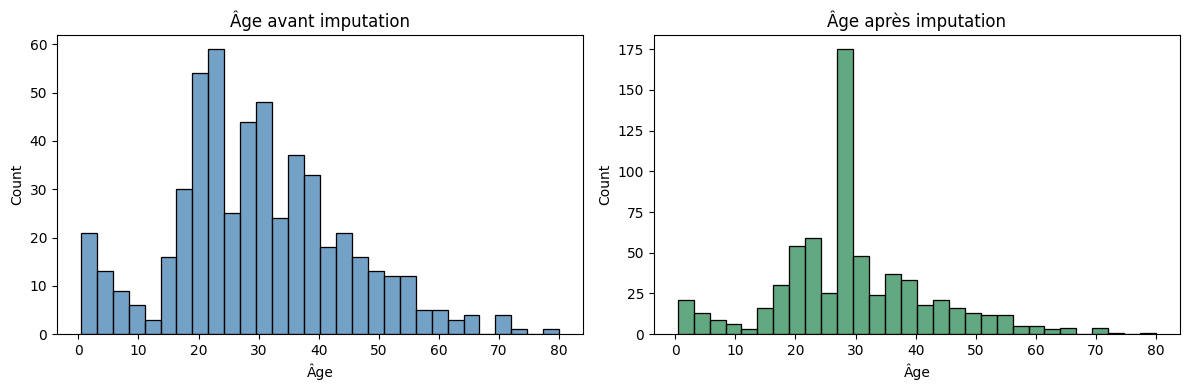

In [132]:
# Comparaison avant et après imputation

from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns

# Imputation sur Train uniquement
imputer_age = SimpleImputer(strategy="median")

age_imputed = imputer_age.fit_transform(
    X_tr[["age"]]
).ravel()

# Afficher la médiane utilisée
print("Médiane utilisée :", imputer_age.statistics_[0])

# Comparer les distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Avant imputation
sns.histplot(
    X_tr["age"].dropna(),
    bins=30,
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Âge avant imputation")
axes[0].set_xlabel("Âge")

# Après imputation
sns.histplot(
    age_imputed,
    bins=30,
    ax=axes[1],
    color="seagreen"
)
axes[1].set_title("Âge après imputation")
axes[1].set_xlabel("Âge")

plt.tight_layout()
plt.show()

Interprétation des histogrammes

Avant imputation :

- Les âges manquants ne sont pas représentés.

- L'histogramme présente uniquement les âges connus.

Après imputation :

- Toutes les observations du Train possèdent désormais un âge.

- Les valeurs manquantes ont été remplacées par la même médiane.

- Une concentration artificielle apparaît autour de cette médiane.

Cette concentration est appelée artefact d'imputation.

<b> Qu'est-ce qu'un artefact d'imputation ?</b>

La médiane est de 30 ans.

Après imputation, trois passagers possèdent un âge de 30 ans, alors qu'un seul avait réellement cet âge.

Conséquence : l'histogramme présente un pic artificiel autour de 30 ans.

Conclusion à tirer

L'imputation par la médiane permet de supprimer les valeurs manquantes, mais elle modifie la distribution des données en créant une concentration artificielle autour de la médiane.

À retenir : 

l'imputation complète les données, mais les valeurs remplacées restent des estimations et non des observations réelles.

## Section 8 — Synthèse à compléter

Question 8.1 — Compléter l'ordre des étapes

Complétez la phrase suivante :

> L'ordre correct des étapes est : audit → \_\_\_\_\_\_ → EDA (sur \_\_\_\_\_\_) → fit du pipeline sur \_\_\_\_\_\_ → transform sur \_\_\_\_\_\_.

  Objectif

Identifier l'ordre correct des étapes de préparation des données en Machine Learning afin d'éviter la fuite de données (Data Leakage).

  Réponse:

L'ordre correct est :

1. Audit : examiner les données et identifier les valeurs manquantes.
2. Split Train/Test : séparer les données en deux ensembles.
3. EDA sur Train : explorer et analyser uniquement les données d'apprentissage.
4. Fit du pipeline sur Train : apprendre les paramètres du prétraitement.
5. Transform sur Test : appliquer au Test les transformations apprises sur Train.

 Conclusion à tirer

> Il faut séparer les données en Train et Test avant d'apprendre les paramètres du prétraitement. Le Test doit rester indépendant afin d'obtenir une évaluation fiable du modèle.


## Question 8.2 — La médiane est préférable à la moyenne pour imputer une variable \_\_\_\_\_\_.

 Objectif

Comprendre dans quel cas il est préférable d'utiliser la médiane plutôt que la moyenne pour remplacer les valeurs manquantes.

 Réponse et explication

La médiane est préférable pour une variable numérique fortement asymétrique ou contenant des valeurs extrêmes.

 Conclusion à tirer

> La médiane est généralement préférable à la moyenne pour imputer une variable numérique fortement asymétrique, car elle est moins sensible aux valeurs extrêmes.

Réponse à compléter :

La médiane est préférable à la moyenne pour imputer une variable <b> fortement asymétrique.</b>


## Question 8.3 — La standardisation centre et réduit, mais ne supprime pas \_\_\_\_\_\_.

 Objectif

Comprendre ce que fait la standardisation avec `StandardScaler` et connaître ses limites.

 Réponse et explication

La standardisation transforme les données pour obtenir :

- Une moyenne proche de 0.
- Un écart-type proche de 1.

La formule utilisée est :

$$
z = \frac{x-\mu}{\sigma}
$$

Cependant, la standardisation ne supprime pas l'asymétrie de la distribution ni les valeurs extrêmes.

| Avant standardisation        | Après standardisation               |
| ---------------------------- | ----------------------------------- |
| Moyenne différente de 0      | Moyenne ≈ 0                         |
| Écart-type différent de 1    | Écart-type ≈ 1                      |
| Distribution asymétrique     | Distribution toujours asymétrique   |
| Présence de valeurs extrêmes | Valeurs extrêmes toujours présentes |

Exemple Titanic :

La variable `fare` présente une forte asymétrie positive (`skew ≈ 4,85`).

Après application de `StandardScaler`, sa moyenne devient proche de 0 et son écart-type proche de 1 sur le Train, mais son coefficient d'asymétrie reste inchangé.

 Conclusion à tirer

> La standardisation modifie l'échelle des données, mais ne corrige pas leur asymétrie et ne supprime pas les valeurs extrêmes.

Réponse à compléter :

La standardisation centre et réduit, mais ne supprime pas <b>l'asymétrie de la distribution.</b>


Pourquoi est-ce important pour certains algorithmes ?

| **Algorithme** | **Standardisation** |
|---|---|
| **kNN** | Très importante, car il utilise les distances. |
| **SVM** | Généralement recommandée. |
| **Régression logistique** | Souvent recommandée, notamment avec régularisation. |
| **Réseaux de neurones** | Souvent utile pour faciliter l'optimisation. |
| **Random Forest** | Généralement non nécessaire. |
| **Arbre de décision** | Généralement non nécessaire. |

 Question 8.4 — Une fuite de données rend l'évaluation \_\_\_\_\_\_.

 Objectif

Comprendre les conséquences d'une fuite de données (Data Leakage) sur l'évaluation d'un modèle de Machine Learning.

 Réponse et explication

Une fuite de données se produit lorsque des informations du Test sont utilisées pendant l'apprentissage ou le prétraitement du modèle.

Attention : 

une fuite de données ne garantit pas toujours une augmentation du score, mais elle compromet la validité de l'évaluation.

Conclusion à tirer

Une fuite de données rend l'évaluation du modèle <b>biaisée et potentiellement trop optimiste</b>, car des informations du Test ont été utilisées pendant la préparation ou l'apprentissage.

Réponse à compléter :

Une fuite de données rend l'évaluation <b>potentiellement trop optimiste.</b>


Question 9.1 — Laquelle des deux méthodes apprend des statistiques : `fit()` ou `transform()` ?

 Objectif

Comprendre la différence entre `fit()` et `transform()` lors du prétraitement des données.

 Réponse et explication

C'est `fit()` qui apprend les statistiques à partir des données.

| Méthode           | Rôle                                        | Exemple avec `StandardScaler`                      |
| ----------------- | ------------------------------------------- | -------------------------------------------------- |
| `fit()`           | Apprend les paramètres à partir des données | Calcule la moyenne et l'écart-type du Train        |
| `transform()`     | Applique les paramètres déjà appris         | Standardise le Test avec les statistiques du Train |
| `fit_transform()` | Combine les deux opérations                 | Apprend et standardise le Train                    |

Exemple dans notre TP Titanic :

```
# Train : apprendre et transformerX_tr_prep = pre.fit_transform(X_tr)

# Test : transformer uniquementX_te_prep = pre.transform(X_te)
```

- Sur Train, le pipeline calcule les médianes, les moyennes, les écarts-types et identifie les catégories.
- Sur Test, il applique les paramètres appris sans les recalculer.

 Conclusion à tirer

> `fit()` apprend les statistiques à partir du Train, tandis que `transform()` applique les transformations à l'aide des paramètres déjà appris.

Réponse courte : C'est `fit()` qui apprend les statistiques.

Question 9.2 — Expliquez le nombre de colonnes obtenu après le prétraitement.

Objectif

Comprendre pourquoi le nombre de colonnes passe de 7 à 12 après le prétraitement avec `ColumnTransformer`.

 Réponse et explication

Dans notre TP Titanic, nous utilisons :

- 4 variables numériques : `age`, `fare`, `sibsp`, `parch`.

- 3 variables catégorielles : `sex`, `embarked`, `pclass`.

Les variables numériques conservent leurs quatre colonnes après l'imputation et la standardisation.

En revanche, le `OneHotEncoder` transforme chaque catégorie en une colonne binaire.

Le nombre total de colonnes est donc :

 4 + 2 + 3 + 3 = 12

 Conclusion à tirer

> Le nombre de colonnes passe de 7 à 12 parce que le One-Hot Encoding transforme les trois variables catégorielles en huit colonnes binaires, tandis que les quatre variables numériques conservent leur nombre initial de colonnes.

Réponse courte : Après le prétraitement, nous obtenons 12 colonnes : 4 numériques et 8 binaires.


 Question 9.3 — Une variable standardisée sur Train a une moyenne de 0,09 sur Test. Est-ce un bug ? Justifiez.

 Objectif

Comprendre pourquoi la moyenne des données standardisées du Test n'est pas nécessairement égale à 0.

 Réponse et explication

Non, ce n'est pas un bug.

Le `StandardScaler` calcule la moyenne et l'écart-type uniquement sur Train, puis utilise ces mêmes paramètres pour transformer Test.

| Ensemble | Opération             | Moyenne après standardisation |
| -------- | --------------------- | ----------------------------- |
| Train    | `fit_transform(X_tr)` | ≈ 0                           |
| Test     | `transform(X_te)`     | Pas nécessairement 0          |

Exemple :

Supposons que, pour la variable `age` :

- Moyenne du Train = 30 ans.
- Écart-type du Train = 10 ans.
- Moyenne du Test = 30,9 ans.

Après standardisation du Test :

$$
z = \frac{30,9-30}{10} = \boxed{0,09}
$$

La moyenne du Test est donc de 0,09, et non de 0.

Cela signifie que les âges du Test sont, en moyenne, légèrement supérieurs à ceux du Train.

 Conclusion à tirer

> Une moyenne de 0,09 sur Test est normale, car la standardisation utilise les statistiques apprises uniquement sur Train. Le Test ne participe pas au calcul de ces paramètres, ce qui évite la fuite de données.

Réponse courte : Non, ce n'est pas un bug. Seul le Train est centré autour de 0 par `StandardScaler`. La moyenne du Test peut être différente de 0.


 Question 9.4 — La standardisation corrige-t-elle l'asymétrie de `fare` ?

 Objectif

Comprendre la différence entre la standardisation et la transformation logarithmique.

 Réponse et explication

Non, la standardisation ne corrige pas l'asymétrie d'une distribution.

Le `StandardScaler` transforme les valeurs pour obtenir une moyenne proche de 0 et un écart-type proche de 1 sur le Train.

Cependant, il ne modifie pas la forme de la distribution.

Dans notre TP Titanic, `fare` présente une forte asymétrie positive (`skew ≈ 4,85`).

| Méthode        | Effet sur les données         | Effet sur l'asymétrie             |
| -------------- | ----------------------------- | --------------------------------- |
| StandardScaler | Centre et réduit les valeurs  | Ne modifie pas l'asymétrie        |
| `np.log1p()`   | Compresse les grandes valeurs | Peut réduire l'asymétrie positive |

Exemple :

- Avant standardisation : `skew(fare) ≈ 4,85`.
- Après standardisation : `skew(fare) ≈ 4,85`.
- Après transformation logarithmique : l'asymétrie peut diminuer.

 Conclusion à tirer

> La standardisation modifie l'échelle des données, mais ne corrige pas leur asymétrie. Une transformation logarithmique peut être utilisée pour réduire une forte asymétrie positive.

Réponse courte : Non, `StandardScaler` ne corrige pas l'asymétrie de `fare` ; il centre et réduit uniquement les valeurs.


 Question 9.5 — La forte différence de survie selon `sex` est-elle une opportunité de modélisation, un enjeu d'équité, ou les deux ?

 Objectif

Comprendre l'importance d'une variable pour la prédiction et les risques de discrimination liés à son utilisation.

 Réponse et explication

Les deux : une opportunité de modélisation et un enjeu d'équité.

Dans notre TP Titanic, les taux de survie calculés sur Train montrent :

| Sexe              | Taux de survie |
| ----------------- | -------------- |
| Femmes (`female`) | 75,21 %        |
| Hommes (`male`)   | 18,43 %        |

A. Opportunité de modélisation

La variable `sex` est fortement associée à la survie.

Elle peut donc aider le modèle à prédire si un passager a survécu ou non et améliorer ses performances.

B. Enjeu d'équité

La différence de survie reflète notamment les pratiques d'évacuation et les inégalités sociales de l'époque.

Dans une application actuelle, utiliser le sexe pour prendre des décisions pourrait entraîner ou reproduire des discriminations.

 Conclusion à tirer

> La variable `sex` constitue une opportunité de modélisation, car elle est fortement associée à la survie. Cependant, son utilisation soulève également un enjeu d'équité, puisqu'elle peut conduire à des prédictions différentes selon le sexe. Il faut donc évaluer à la fois la performance du modèle et les risques de discrimination.

Réponse courte à retenir :

La différence de survie selon `sex` représente les deux : une information utile pour la prédiction et un enjeu d'équité. Une variable prédictive n'est pas nécessairement appropriée dans toutes les applications.
